In [1]:
#Aim: To build an image classification model by loading and preprocessing image data, defining the model architecture, training the model, and estimating its performance.

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras import layers

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

In [3]:
print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)

print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


In [4]:
# normalize dataset
x_train = x_train / 255.0
x_test = x_test / 255.0

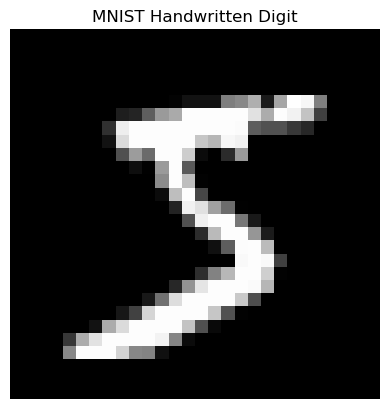

Actual Digit: 5


In [5]:
plt.imshow(x_train[0], cmap='gray')
plt.title("MNIST Handwritten Digit")
plt.axis('off')
plt.show()

print("Actual Digit:", y_train[0])

In [6]:
# reshape image CNN expects image data in the format:
#(Number of images, Height, Width, Channels)
#Here:
#- Height = 28
#- Width = 28
#- Channels = 1 because MNIST images are grayscale.

x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

In [7]:
model = keras.Sequential([

    layers.Conv2D(32, (3,3), activation='relu',
                  input_shape=(28,28,1)),

    layers.MaxPooling2D((2,2)),

    layers.Flatten(),

    layers.Dense(64, activation='relu'),

    layers.Dense(10, activation='softmax')
])

C:\Users\Asus\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [8]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [9]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 5408)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │         346,176 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 347,146 (1.32 MB)

 Trainable params: 347,146 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9461 - loss: 0.1820 - val_accuracy: 0.9822 - val_loss: 0.0718
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9818 - loss: 0.0612 - val_accuracy: 0.9842 - val_loss: 0.0566
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9872 - loss: 0.0413 - val_accuracy: 0.9862 - val_loss: 0.0530
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9908 - loss: 0.0290 - val_accuracy: 0.9872 - val_loss: 0.0522
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9927 - loss: 0.0223 - val_accuracy: 0.9890 - val_loss: 0.0497


In [11]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9858 - loss: 0.0416 
Test Loss: 0.04155349358916283
Test Accuracy: 0.98580002784729


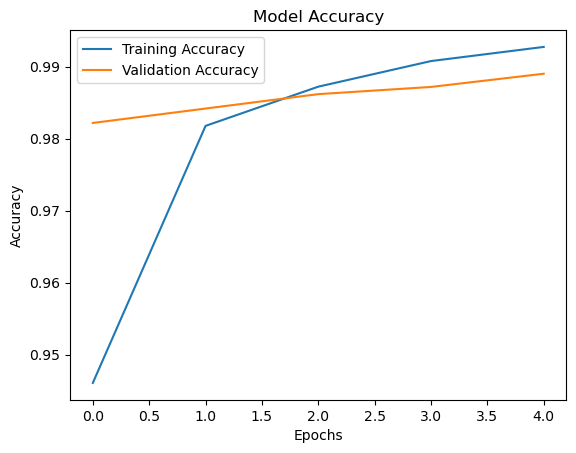

In [12]:
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

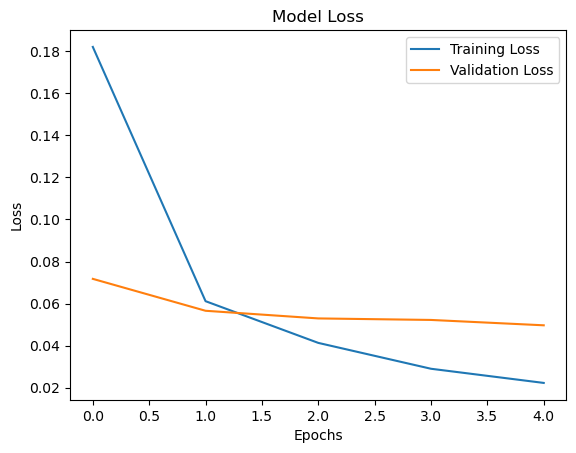

In [13]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step


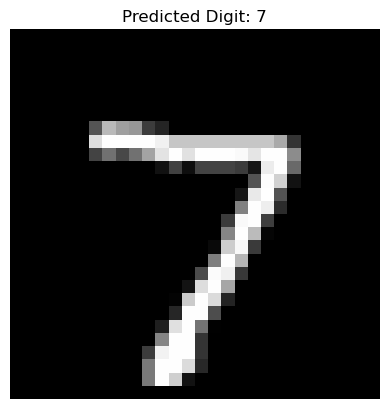

Actual Digit: 7
Predicted Digit: 7


In [14]:
prediction = model.predict(x_test[:1])

predicted_digit = np.argmax(prediction)

plt.imshow(x_test[0].reshape(28,28), cmap='gray')
plt.title("Predicted Digit: " + str(predicted_digit))
plt.axis('off')
plt.show()

print("Actual Digit:", y_test[0])
print("Predicted Digit:", predicted_digit)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step  


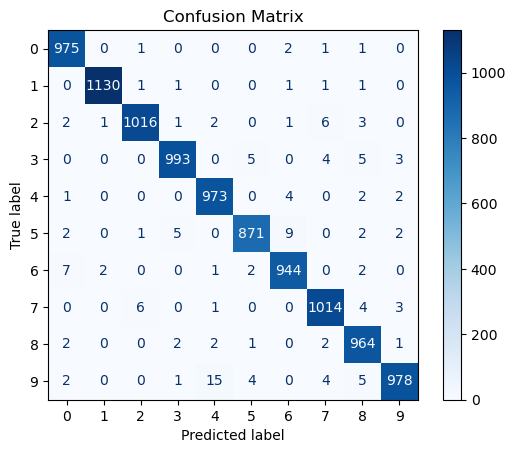

In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Predict all test images
y_pred = model.predict(x_test)

# Convert probabilities into predicted digits
y_pred = np.argmax(y_pred, axis=1)

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm)

disp.plot(cmap='Blues')
plt.title("Confusion Matrix")
plt.show()

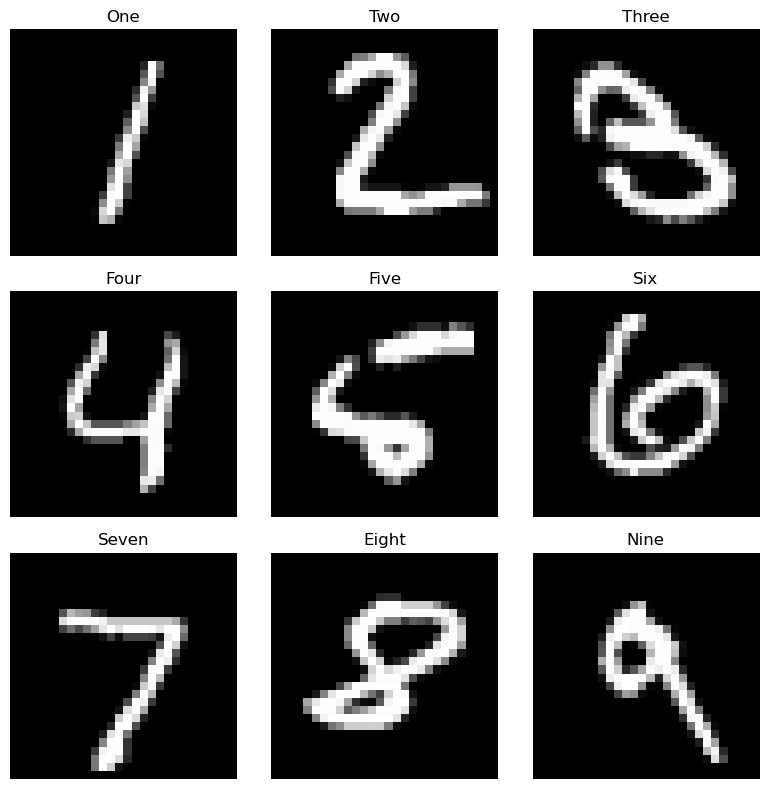

In [18]:
digit_names = {
    1: "One",
    2: "Two",
    3: "Three",
    4: "Four",
    5: "Five",
    6: "Six",
    7: "Seven",
    8: "Eight",
    9: "Nine"
}

plt.figure(figsize=(8, 8))

for digit in range(1, 10):

    index = np.where(y_test == digit)[0][0]

    plt.subplot(3, 3, digit)
    plt.imshow(x_test[index].reshape(28, 28), cmap='gray')
    plt.title(digit_names[digit])
    plt.axis('off')

plt.tight_layout()
plt.show()